This workbook is focused on importing, cleaning, and processing PM2.5 data.

## Importing Initial Libraries

In [5]:
## importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import geopandas as gpd
import numpy as np

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Importing PM2.5 Dataset

In [7]:
## API used to download wildfire season PM2.5 data from U.S. EPA web server (https://aqs.epa.gov/)
## Defining file location here, and reading data into a pandas dataframe
file_path = "/content/drive/MyDrive/ATMS596/IL_daily_PM25_Jun_Sep_2015_2025_AQS_API.csv"
pm_df = pd.read_csv(file_path)

## Exploratory Data Analysis and Dataset Cleaning
Includes filtering for specific sample duration, removing duplicates, etc.

In [8]:
## checking out column headers
print(pm_df.columns)
print(pm_df.head())

Index(['state_code', 'county_code', 'site_number', 'parameter_code', 'poc',
       'latitude', 'longitude', 'datum', 'parameter', 'sample_duration_code',
       'sample_duration', 'pollutant_standard', 'date_local',
       'units_of_measure', 'event_type', 'observation_count',
       'observation_percent', 'validity_indicator', 'arithmetic_mean',
       'first_max_value', 'first_max_hour', 'aqi', 'method_code', 'method',
       'local_site_name', 'site_address', 'state', 'county', 'city',
       'cbsa_code', 'cbsa', 'date_of_last_change'],
      dtype='object')
   state_code  county_code  site_number  parameter_code  poc   latitude  \
0          17          201           13           88101    1  42.263081   
1          17          201           13           88101    1  42.263081   
2          17          201           13           88101    1  42.263081   
3          17          201           13           88101    1  42.263081   
4          17          201           13           88101  

In [9]:
## Data cleaning -
## Checking formate of date column
pm_df["date_local"].dtype

dtype('O')

In [10]:
## For next steps, I will need the date column (date_local) to be in datetime format
pm_df["date_local"] = pd.to_datetime(pm_df["date_local"])
pm_df["date_local"].dtype

dtype('<M8[ns]')

In [11]:
## I want to identify what sample durations are available
## We will select one consistent sample duration for the project
pm_df['sample_duration'].value_counts()

,count
sample_duration,
24-HR BLK AVG,175106
24 HOUR,66761
1 HOUR,27730


In [12]:
## 24-Hr Block Averages are calculated by averaging continuous monitoring data.
## This is what is used to determine attainment and compliance with NAAQS.
## 24-Hr sample duration is a physical sample collected over 24-hours.
## For this project, keep only 24-hour block averages
pm_daily = pm_df.loc[pm_df["sample_duration"] == "24-HR BLK AVG"].copy()

In [13]:
pm_daily.head()

,state_code,county_code,site_number,parameter_code,poc,latitude,longitude,datum,parameter,sample_duration_code,...,method_code,method,local_site_name,site_address,state,county,city,cbsa_code,cbsa,date_of_last_change
3960,17,19,1001,88101,3,40.05278,-88.37251,WGS84,PM2.5 - Local Conditions,X,...,183,Thermo Scientific 5014i or FH62C14-DHS w/VSCC ...,ISWS CLIMATE STATION,TWP RD 500 E.,Illinois,Champaign,Bondville,16580.0,"Champaign-Urbana, IL",2024-05-21
3964,17,19,1001,88101,3,40.05278,-88.37251,WGS84,PM2.5 - Local Conditions,X,...,183,Thermo Scientific 5014i or FH62C14-DHS w/VSCC ...,ISWS CLIMATE STATION,TWP RD 500 E.,Illinois,Champaign,Bondville,16580.0,"Champaign-Urbana, IL",2024-05-21
3965,17,19,1001,88101,3,40.05278,-88.37251,WGS84,PM2.5 - Local Conditions,X,...,183,Thermo Scientific 5014i or FH62C14-DHS w/VSCC ...,ISWS CLIMATE STATION,TWP RD 500 E.,Illinois,Champaign,Bondville,16580.0,"Champaign-Urbana, IL",2024-05-21
3966,17,19,1001,88101,3,40.05278,-88.37251,WGS84,PM2.5 - Local Conditions,X,...,183,Thermo Scientific 5014i or FH62C14-DHS w/VSCC ...,ISWS CLIMATE STATION,TWP RD 500 E.,Illinois,Champaign,Bondville,16580.0,"Champaign-Urbana, IL",2024-05-21
3967,17,19,1001,88101,3,40.05278,-88.37251,WGS84,PM2.5 - Local Conditions,X,...,183,Thermo Scientific 5014i or FH62C14-DHS w/VSCC ...,ISWS CLIMATE STATION,TWP RD 500 E.,Illinois,Champaign,Bondville,16580.0,"Champaign-Urbana, IL",2024-05-21


In [14]:
## Ultimately we want one data point per station per day.
## First I will make a new column to hold unique station ids.
## This can also be used later for plotting time series at each station, and grouping by station.
pm_daily["station_id"] = (pm_daily["city"].astype(str) + "_" + pm_daily["site_number"].astype(str))

In [15]:
## How many unique stations do we have data for?
print(pm_daily["station_id"].nunique())

25


In [16]:
## Next reviewing to see if there any multiple rows per station each day
## Count the number of records per station per day
station_day_count_1 = pm_daily.groupby(["station_id", "date_local"]).size()
print(station_day_count_1.value_counts().sort_index())

2        1
4        4
8     9373
13     120
16    5501
32     329
Name: count, dtype: int64


In [17]:
## Since there are >9,000 station-days days with 8 entries, I want to determine
## which variable is causing all the repeat values.
## Find one of the station-days with 8 records
example_8r_station, example_8r_date = (station_day_count_1[station_day_count_1 == 8].index[0])
example_8r = pm_daily[
    (pm_daily["station_id"] == example_8r_station) &
    (pm_daily["date_local"] == example_8r_date)
]
# and display all 8 records
print(example_8r.to_string(index=False))

 state_code  county_code  site_number  parameter_code  poc  latitude  longitude datum                parameter sample_duration_code sample_duration pollutant_standard date_local            units_of_measure event_type  observation_count  observation_percent validity_indicator  arithmetic_mean  first_max_value  first_max_hour  aqi  method_code                                                                             method                     local_site_name        site_address    state  county  city  cbsa_code             cbsa date_of_last_change station_id
         17          119          120           88101    3 38.901362 -90.146308 NAD83 PM2.5 - Local Conditions                    X   24-HR BLK AVG  PM25 24-hour 2006 2024-08-01 Micrograms/cubic meter (LC)  No Events                  1                100.0                  Y              7.5              7.5               0 42.0          636 Teledyne T640 at 5.0 LPM w/Network Data Alignment enabled - Broadband spectroscopy ALTON HO

In [18]:
## Based on a review of the results above, there are multiple identical rows for
## different federal standards, but the mean PM2.5 values are the same.
## Filtering to keep the row for the PM2.5 24-hr 2012 standard only.
pm_daily = pm_daily.loc[pm_daily["pollutant_standard"] == "PM25 24-hour 2012"].copy()

In [19]:
## Checking again for duplicate rows per station-day.
station_day_count_2 = pm_daily.groupby(["station_id", "date_local"]).size()
print(station_day_count_2.value_counts().sort_index())

1    9373
2    5621
4     329
Name: count, dtype: int64


In [20]:
## Find station-days that still have more than one record
duplicate_days = station_day_count_2[station_day_count_2 > 1]

## Select the first duplicate example
example_dup_station, example_dup_date = duplicate_days.index[0]
example_dup= pm_daily[
    (pm_daily["station_id"] == example_dup_station) &
    (pm_daily["date_local"] == example_dup_date)
]
# and display records
print(example_dup.to_string(index=False))

 state_code  county_code  site_number  parameter_code  poc  latitude  longitude datum                parameter sample_duration_code sample_duration pollutant_standard date_local            units_of_measure      event_type  observation_count  observation_percent validity_indicator  arithmetic_mean  first_max_value  first_max_hour  aqi  method_code                                                        method      local_site_name  site_address    state    county      city  cbsa_code                 cbsa date_of_last_change     station_id
         17           19         1001           88101   23  40.05278  -88.37251 WGS84 PM2.5 - Local Conditions                    X   24-HR BLK AVG  PM25 24-hour 2012 2022-09-02 Micrograms/cubic meter (LC)       No Events                  1                100.0                  Y              7.5              7.5               0 42.0          736 Teledyne T640 at 5.0 LPM (Corrected) - Broadband spectroscopy ISWS CLIMATE STATION TWP RD 500 E. Illinois Cha

In [21]:
## Based on review of the resutls, one of the columns that differs is method_code.
## Method 736 is "corrected". EPA recommends using 736 when available -
## Source: (https://aqs.epa.gov/aqsweb/airdata/Data_Advisory_PM25_88101_Pregen_Files.pdf)
## So for rows when there are two options, method 736 should be used.
## This can be done by sorting. If only 236 is available, use that row. If 236 and 736 are avaialble,
## keep the second row (736).

pm_daily = pm_daily.sort_values("method_code").drop_duplicates(
    subset=["station_id", "date_local"], keep="last")

In [22]:
## Checking again for duplicate rows per station-days.
station_day_count_3 = pm_daily.groupby(["station_id", "date_local"]).size()
print(station_day_count_3.value_counts().sort_index())

1    15323
Name: count, dtype: int64


In [23]:
## Now checking data coverage per station

station_coverage = (pm_daily.groupby("station_id").agg(first_date=("date_local", "min"),
        last_date=("date_local", "max"),days_with_data=("date_local", "nunique"))
    .reset_index()
)
station_coverage["coverage_years"] = ((station_coverage["last_date"] - station_coverage["first_date"]).dt.days / 365)
print(station_coverage.to_string(index=False))

                          station_id first_date  last_date  days_with_data  coverage_years
                           Alton_120 2024-08-01 2024-09-30              61        0.164384
                      Bondville_1001 2015-06-01 2024-09-30            1140        9.339726
                      Braidwood_1011 2017-06-01 2024-09-30             910        7.336986
                              Cary_1 2021-06-10 2024-09-30             472        3.309589
                         Champaign_6 2024-06-01 2024-09-30             122        0.331507
                          Decatur_13 2018-06-01 2024-09-30             843        6.336986
                    Des Plaines_4007 2017-06-01 2024-09-30             793        7.336986
                 East Saint Louis_10 2022-06-01 2024-09-30             351        2.334247
                   Granite City_1007 2024-06-01 2024-09-30             105        0.331507
                    Jerseyville_1001 2017-06-03 2017-08-09              62        0.183562

In [24]:
## I think it makes sense to trim off the stations that have data for less than one year
## Justification for this is that the thresholds will be based on annual averages per station-year
## so less than one year of data will generate a skewed threshold value.

eligible_stations = station_coverage.loc[station_coverage["coverage_years"] >= 1,"station_id"]
pm_daily_filtered = pm_daily[pm_daily["station_id"].isin(eligible_stations)].copy()

In [25]:
## Confirming nothing weird added duplicates
## And checking how many data points are still available

station_day_count_4 = pm_daily_filtered.groupby(["station_id", "date_local"]).size()
print(station_day_count_4.value_counts().sort_index())

1    14731
Name: count, dtype: int64


In [26]:
## How many unique stations do we still have data for?
print(pm_daily_filtered["station_id"].nunique())

19


In [27]:
## Yay!! naming the cleaned dataset "pm"
pm = pm_daily_filtered

## Preliminary Data Visualization of Cleaned Data

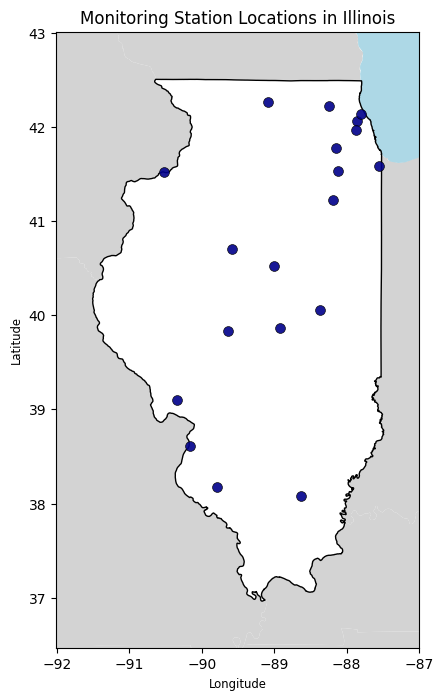

In [28]:
## For mapping, importing Illinois state boundaries.
states_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
states = gpd.read_file(states_url)
illinois = states[states["STUSPS"] == "IL"].copy()

## Also importing Lake Michigan boundaries for mapping.
lakes_url = "https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_lakes.zip"
lakes = gpd.read_file(lakes_url)
lake_michigan = lakes[lakes["name"] == "Lake Michigan"].copy()

fig, ax = plt.subplots(figsize=(8, 8))

##cI want the background to be grey, so plot all states in gray
states.plot(ax=ax, facecolor="lightgray")

## Plot Lake Michigan first in blue
lake_michigan.plot(ax=ax, facecolor="lightblue",edgecolor="lightblue",zorder=1)

## Plot Illinois on top in white. I already have illinois geometry defined from above
illinois.plot(ax=ax,facecolor="white",edgecolor="black",linewidth=1,zorder=2)

## For this plot, I'm making a new dataframe to hold only one row per monitoring station_id
stations = pm.drop_duplicates(subset="station_id")

## Plot
scatter = ax.scatter(stations["longitude"],stations["latitude"],s=50,alpha=0.9,color="darkblue",edgecolor="black",linewidth=0.5,zorder=3)

## Zoom to Illinois with padding
minx, miny, maxx, maxy = illinois.total_bounds
ax.set_xlim(minx - 0.5, maxx + 0.5)
ax.set_ylim(miny - 0.5, maxy + 0.5)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Monitoring Station Locations in Illinois")

plt.show()

<Figure size 2000x1200 with 0 Axes>

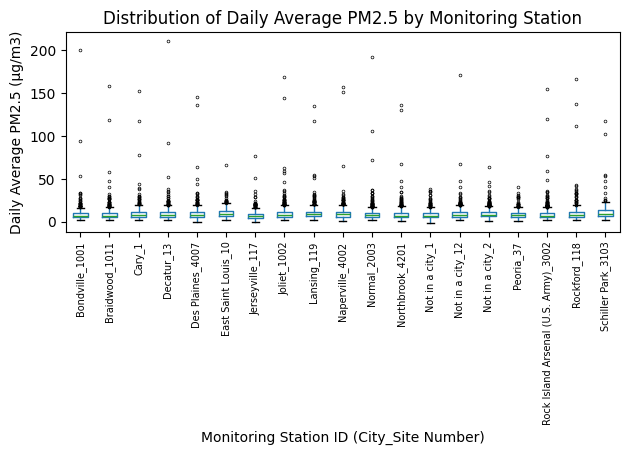

In [29]:
## Plot the distribution of daily averages for each station for all years
plt.figure(figsize=(20,12))

pm.boxplot(column="arithmetic_mean",by="station_id",grid=False,flierprops=dict(marker='o',markersize=2,markeredgewidth=0.5))

plt.xlabel("Monitoring Station ID (City_Site Number)")
plt.ylabel("Daily Average PM2.5 (µg/m3)")
plt.title("Distribution of Daily Average PM2.5 by Monitoring Station")
plt.suptitle("")
plt.xticks(rotation=90, fontsize=7)

plt.tight_layout()
plt.show()

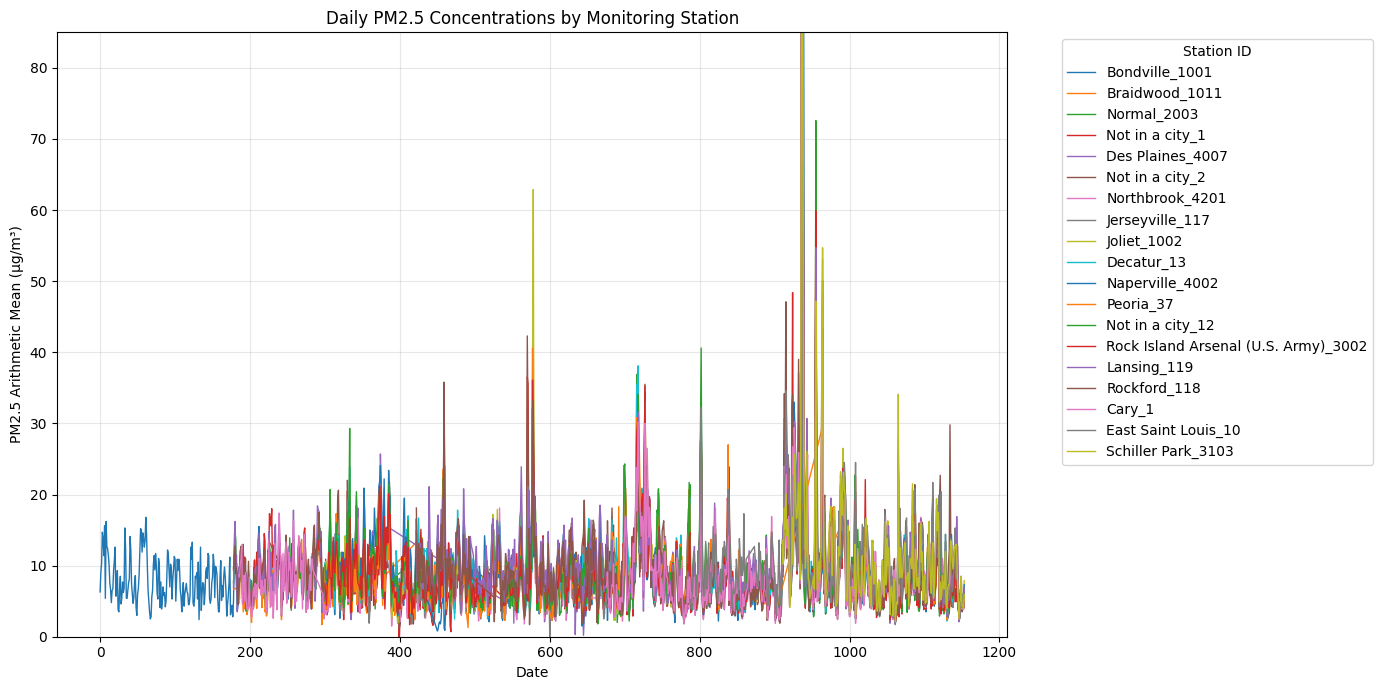

In [30]:
## I also want to view a time series of data points for each station
## First make sure data is sorted by date
## Convert date_local to datetime
pm["date_local"] = pd.to_datetime(pm["date_local"])
pm = pm.sort_values("date_local").copy()
pm["plot_day"] = pm.groupby("date_local").ngroup()

## Create the plot
plt.figure(figsize=(14, 7))

## loop through each unique station id, and plot arithmetic mean over time
for station in pm["station_id"].unique():
    station_data = pm[pm["station_id"] == station]

    plt.plot(
        station_data["plot_day"],
        station_data["arithmetic_mean"],
        label=station,
        linewidth=1
    )

plt.xlabel("Date")
plt.ylabel("PM2.5 Arithmetic Mean (µg/m³)")
plt.title("Daily PM2.5 Concentrations by Monitoring Station")
plt.legend(title="Station ID", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.ylim(0, 85)
plt.tight_layout()
plt.show()

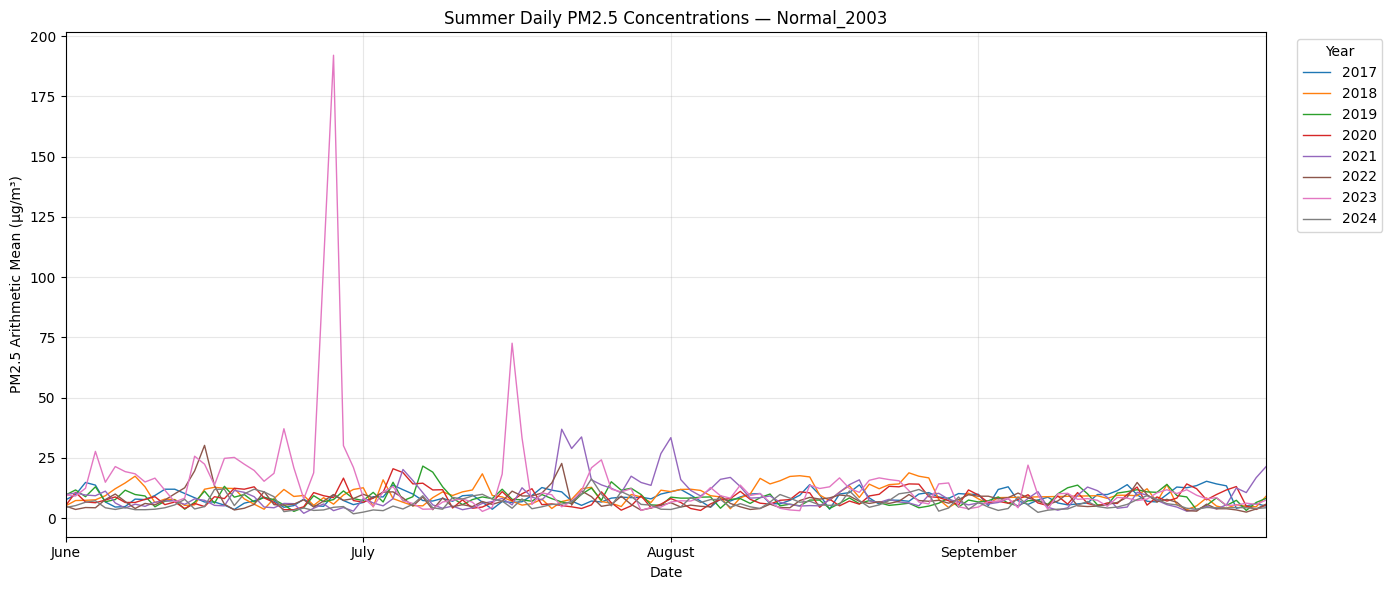

In [31]:
## More data visualization
## Filter show data from one station, from June–September for all available years
station_data = pm[
    (pm["station_id"] == "Normal_2003") &
    (pm["date_local"].dt.month.between(6, 9))
].copy()

## Extract year and day of year for plotting, save to station_data
station_data["year"] = station_data["date_local"].dt.year
station_data["summer_date"] = station_data["date_local"].apply(
    lambda d: d.replace(year=2000)
)

## Create plot
fig, ax = plt.subplots(figsize=(14, 6))

## Loop through plotting each year
for year, group in station_data.groupby("year"):
    group = group.sort_values("summer_date")

    ax.plot(
        group["summer_date"],
        group["arithmetic_mean"],
        label=str(year),
        linewidth=1
    )

ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 Arithmetic Mean (µg/m³)")
ax.set_title("Summer Daily PM2.5 Concentrations — Normal_2003")
ax.set_xlim(pd.Timestamp("2000-06-01"), pd.Timestamp("2000-09-30"))
ax.set_xticks(pd.to_datetime(["2000-06-01", "2000-07-01", "2000-08-01", "2000-09-01"]))
ax.set_xticklabels(["June", "July", "August", "September"])
ax.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

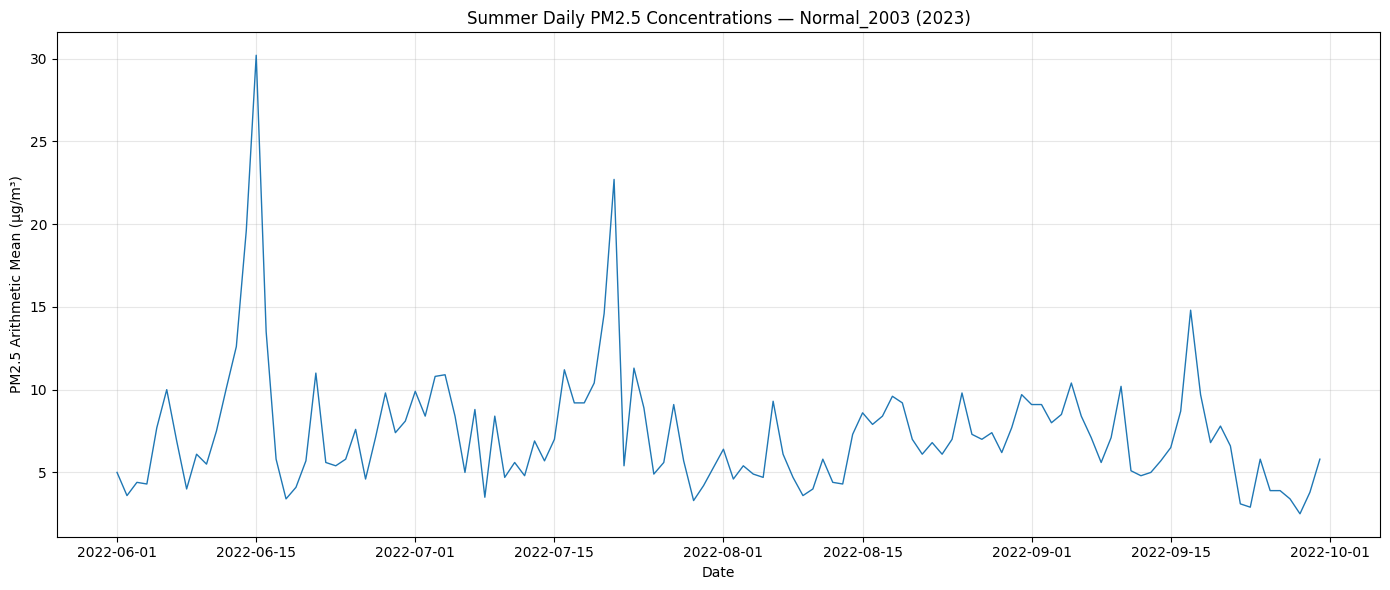

In [32]:
## More data visualization
## Filter to one station, one year, and June–September
station_data = pm[
    (pm["station_id"] == "Normal_2003") &
    (pm["date_local"].dt.year == 2022) &
    (pm["date_local"].dt.month.between(6, 9))
].sort_values("date_local")

## Plot
plt.figure(figsize=(14, 6))
plt.plot(station_data["date_local"],station_data["arithmetic_mean"],linewidth=1)
plt.xlabel("Date")
plt.ylabel("PM2.5 Arithmetic Mean (µg/m³)")
plt.title("Summer Daily PM2.5 Concentrations — Normal_2003 (2023)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Data Processing

### Setting Thresholds

In [33]:
## To determine thresholds, first need to group by station id and by year
## First extract year from date_local
pm["year"] = pm["date_local"].dt.year

# Group by station and year
station_year_groups = pm.groupby(["station_id", "year"])

# Calculate percentiles for each station-year
station_year_p75 = station_year_groups["arithmetic_mean"].quantile(0.75)
station_year_p90 = station_year_groups["arithmetic_mean"].quantile(0.90)

## reset index so columns behave for merging back into main df
## "sy" stands for station-year
station_year_p75 = station_year_p75.reset_index(name='sy_p75')
station_year_p90 = station_year_p90.reset_index(name='sy_p90')

## merge back into daily data df.
pm = pm.merge(station_year_p75,on=['station_id','year'])
pm = pm.merge(station_year_p90,on=['station_id','year'])

In [34]:
## Checkpoint
## Create verification table to check whether threshold values make sense, and were
## calculated indiviudally per station and per year
station_year_thresholds = station_year_p75.merge(station_year_p90,on=["station_id", "year"])
print(station_year_thresholds.to_string(index=False))

                          station_id  year  sy_p75  sy_p90
                      Bondville_1001  2015  11.800   14.30
                      Bondville_1001  2016   9.500   11.02
                      Bondville_1001  2017  10.200   12.09
                      Bondville_1001  2018  10.700   12.58
                      Bondville_1001  2019   8.100   10.14
                      Bondville_1001  2020   8.400   10.70
                      Bondville_1001  2021  10.600   14.71
                      Bondville_1001  2022   8.400   10.70
                      Bondville_1001  2023  13.325   19.78
                      Bondville_1001  2024   8.800   11.80
                      Braidwood_1011  2017   9.500   11.15
                      Braidwood_1011  2018   9.475   11.88
                      Braidwood_1011  2019  10.100   12.05
                      Braidwood_1011  2020   9.150   11.70
                      Braidwood_1011  2021  10.600   14.40
                      Braidwood_1011  2022   8.300    9.

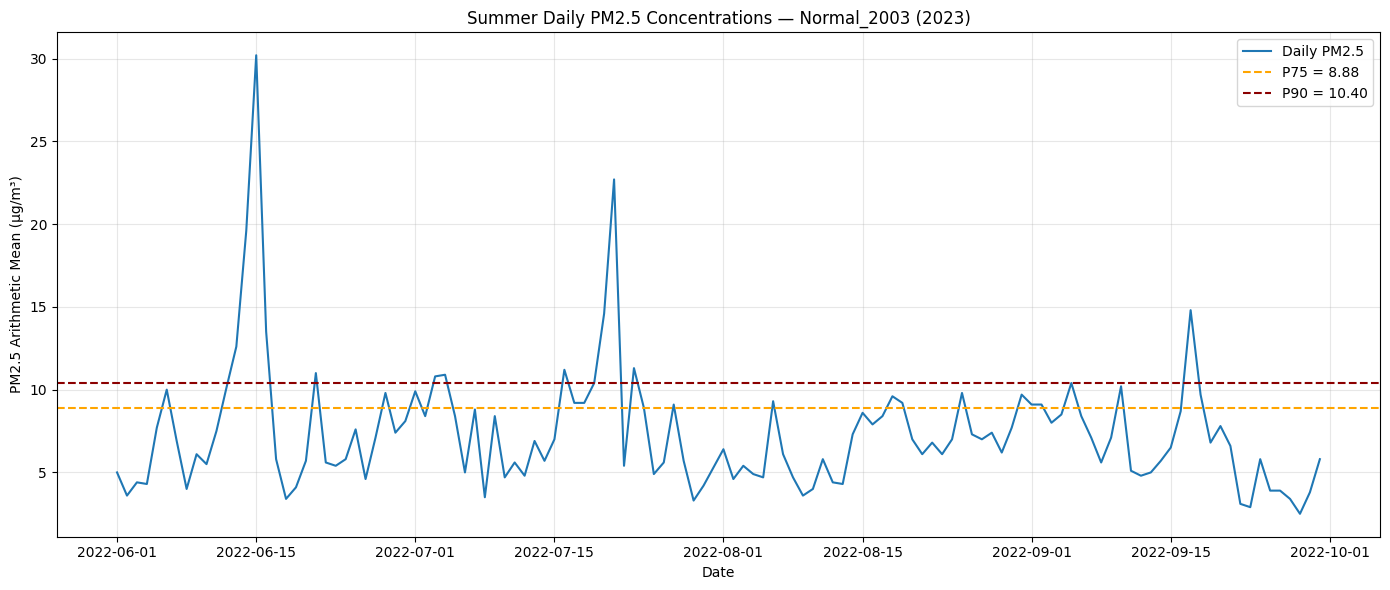

In [35]:
## Checkpoint
## Filter to one station, one year, and June–September, and visualize thresholds
station_data = pm[
    (pm["station_id"] == "Normal_2003") &
    (pm["date_local"].dt.year == 2022) &
    (pm["date_local"].dt.month.between(6, 9))
].sort_values("date_local")

## Get the station-year thresholds (same for every row in this group)
p75 = station_data["sy_p75"].iloc[0]
p90 = station_data["sy_p90"].iloc[0]

## Plot
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(station_data["date_local"],station_data["arithmetic_mean"],label="Daily PM2.5")

## Add threshold lines
ax.axhline(p75, linestyle="--", linewidth=1.5, color='orange',label=f"P75 = {p75:.2f}")
ax.axhline(p90, linestyle="--", linewidth=1.5, color='darkred',label=f"P90 = {p90:.2f}")

ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 Arithmetic Mean (µg/m³)")
ax.set_title("Summer Daily PM2.5 Concentrations — Normal_2003 (2023)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

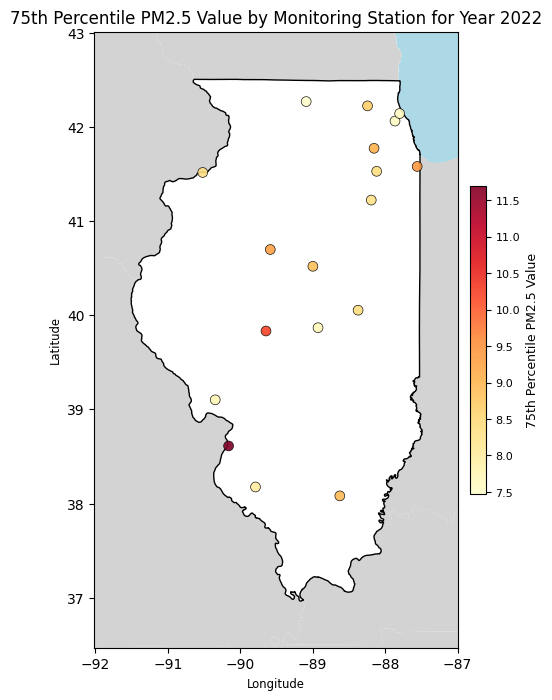

In [36]:
## Visualizing P75 threshold values across monitoring stations, using example year 2022
## For plotting, get 2022 data
pm_2022 = pm[pm["date_local"].dt.year == 2022].copy()

## and pull one P75 threshold and location (lat/lon) per station
station_ps = (
    pm_2022.groupby("station_id")
    .agg(
        p75=("sy_p75", "first"),
        longitude=("longitude", "first"),
        latitude=("latitude", "first")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 8))

## Same code block as used above for setup
states.plot(ax=ax, facecolor="lightgray")
lake_michigan.plot(ax=ax, facecolor="lightblue",edgecolor="lightblue",zorder=1)
illinois.plot(ax=ax,facecolor="white",edgecolor="black",linewidth=1,zorder=2)

## Plot each station-specific p75 value
scatter = ax.scatter(station_ps["longitude"],station_ps["latitude"],c=station_ps["p75"],
    cmap="YlOrRd",s=50,alpha=0.9,edgecolor="black",linewidth=0.5,zorder=3)

## Add colorbar
cbar = plt.colorbar(scatter,ax=ax,shrink=0.5,pad=0.02)
cbar.set_label("75th Percentile PM2.5 Value",fontsize=9)
cbar.ax.tick_params(labelsize=8)

## Zoom to Illinois with padding
minx, miny, maxx, maxy = illinois.total_bounds
ax.set_xlim(minx - 0.5, maxx + 0.5)
ax.set_ylim(miny - 0.5, maxy + 0.5)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("75th Percentile PM2.5 Value by Monitoring Station for Year 2022")

plt.show()

## Identifying High Surface PM2.5 Event Dates

High Surface PM2.5 Event Dates must meet the following two criterion:

Criteria 1: At least one station exceeds its applicable 90th percentile threshold for that date. This criterion is intended to reflect that the concentrations of PM2.5 are extremely high in comparison to typical conditions for that station and that year.

Criteria 2: At least half of the stations exceed their applicable 75th percentile thresholds. This criterion in intended to ensure that event dates have widespread effects where concentrations of PM2.5 are higher than usual on a broad scale.

In [37]:
## create Boolean (t/f) column for whether each day exceeds the applicable station-year thresholds
pm["exceeds_p75"] = pm["arithmetic_mean"] > pm["sy_p75"]
pm["exceeds_p90"] = pm["arithmetic_mean"] > pm["sy_p90"]

# ---Criteria 1---
## Adding a column for whether date meets criteria 1
pm["meets_criteria1"] = pm["exceeds_p90"]

# Count stations exceeding P90 on each date
n_stations_exceeds_p90 = (
    pm[pm["exceeds_p90"]]
    .groupby("date_local")["station_id"]
    .nunique()
    .rename("n_stations_exceeds_p90")
    .reset_index()
)
# Merge counts back into pm
pm = pm.merge(n_stations_exceeds_p90, on="date_local", how="left")

pm["n_stations_exceeds_p90"] = pm["n_stations_exceeds_p90"].fillna(0)

# At least one station must exceed P90
pm["meets_criteria1"] = pm["n_stations_exceeds_p90"] >= 1

# ---Criteria 2---
## Identify the number of unique stations that exceed their p75 on each date
## First, making a temporary df holding only observations where the station exceeds its P75
p75_exceed = pm[pm['exceeds_p75']].copy()

# Count stations exceeding P75 on each date
n_stations_exceeds_p75 = (
    p75_exceed.groupby("date_local")["station_id"]
    .nunique()
    .rename("n_stations_exceeds_p75")
    .reset_index()
)

## Merge counts back into the pm dataframe
pm = pm.merge(n_stations_exceeds_p75, on="date_local", how="left")

## Flag dates when at least half stations exceed P75
pm["meets_criterion2"] = pm["n_stations_exceeds_p75"] >= np.ceil(pm["station_id"].nunique() / 2)

# ---Event Dates---
pm["meets_both_criteria"] = (pm["meets_criteria1"] & pm["meets_criterion2"])
event_dates = (pm.loc[pm['meets_both_criteria'], 'date_local'].drop_duplicates().sort_values())
print(event_dates)

1175    2018-06-16
1189    2018-06-17
1380    2018-07-01
1531    2018-07-12
1545    2018-07-13
           ...    
14055   2024-08-26
14074   2024-08-27
14372   2024-09-12
14486   2024-09-18
14505   2024-09-19
Name: date_local, Length: 150, dtype: datetime64[ns]


In [38]:
## Count event dates per year
event_dates_per_year = event_dates.groupby(event_dates.dt.year).size()
print(event_dates_per_year)

date_local
2018    17
2019    14
2020    19
2021    22
2022    24
2023    29
2024    25
Name: date_local, dtype: int64


In [39]:
## saving list to my drive
# event_dates.to_csv('/content/drive/MyDrive/pm_event_days.csv', index=False)

In [40]:
## and saving pm dataframe to my drive
# pm.to_csv('/content/drive/MyDrive/pm.csv', index=False)

##Visualizations of Event Dates

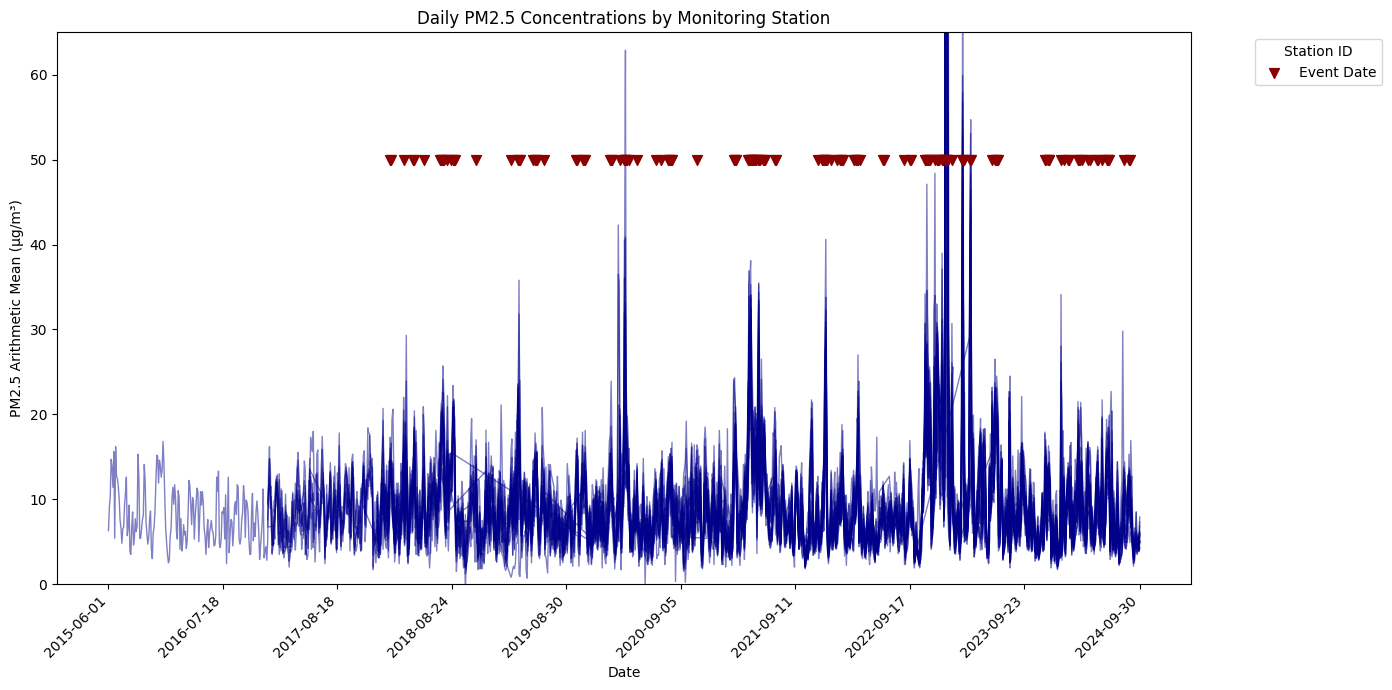

In [59]:
## I want to create a time-series plot that shows data across all the stations
## and includes markers for each event date

## Create the plot
plt.figure(figsize=(14, 7))

## loop through each unique station id, and plot arithmetic mean over time.
## The stations can be the same color for this plot
for station in pm["station_id"].unique():
    station_data = pm[pm["station_id"] == station]

    plt.plot(station_data["plot_day"],station_data["arithmetic_mean"],
        color="darkblue",linewidth=1,alpha=0.5)

## Then I want to add markers for event dates
## first make sure my event_dates series is saved as datetime
event_dates = pd.to_datetime(event_dates)

## Get the plot_day corresponding to each event date
event_plot_days = (pm.loc[pm["date_local"].isin(event_dates), ["date_local", "plot_day"]]
    .drop_duplicates())

## Plot event markers along the top of the chart
plt.scatter(event_plot_days["plot_day"],[50] * len(event_plot_days),
    color="darkred",marker="v",s=50,label="Event Date",zorder=5)

## Create x-axis labels using actual dates
date_ticks = pm[["plot_day", "date_local"]].drop_duplicates("plot_day")

## Set tick locations and labels
ax = plt.gca()
tick_days = np.linspace(pm["plot_day"].min(),pm["plot_day"].max(),10, dtype=int)
tick_dates = date_ticks.set_index("plot_day").loc[tick_days, "date_local"]

ax.set_xticks(tick_days)
ax.set_xticklabels(pd.to_datetime(tick_dates).dt.strftime("%Y-%m-%d"),
    rotation=45, ha="right")

plt.xlabel("Date")
plt.ylabel("PM2.5 Arithmetic Mean (µg/m³)")
plt.title("Daily PM2.5 Concentrations by Monitoring Station")
plt.legend(title="Station ID", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.ylim(0, 65)
plt.tight_layout()
plt.show()


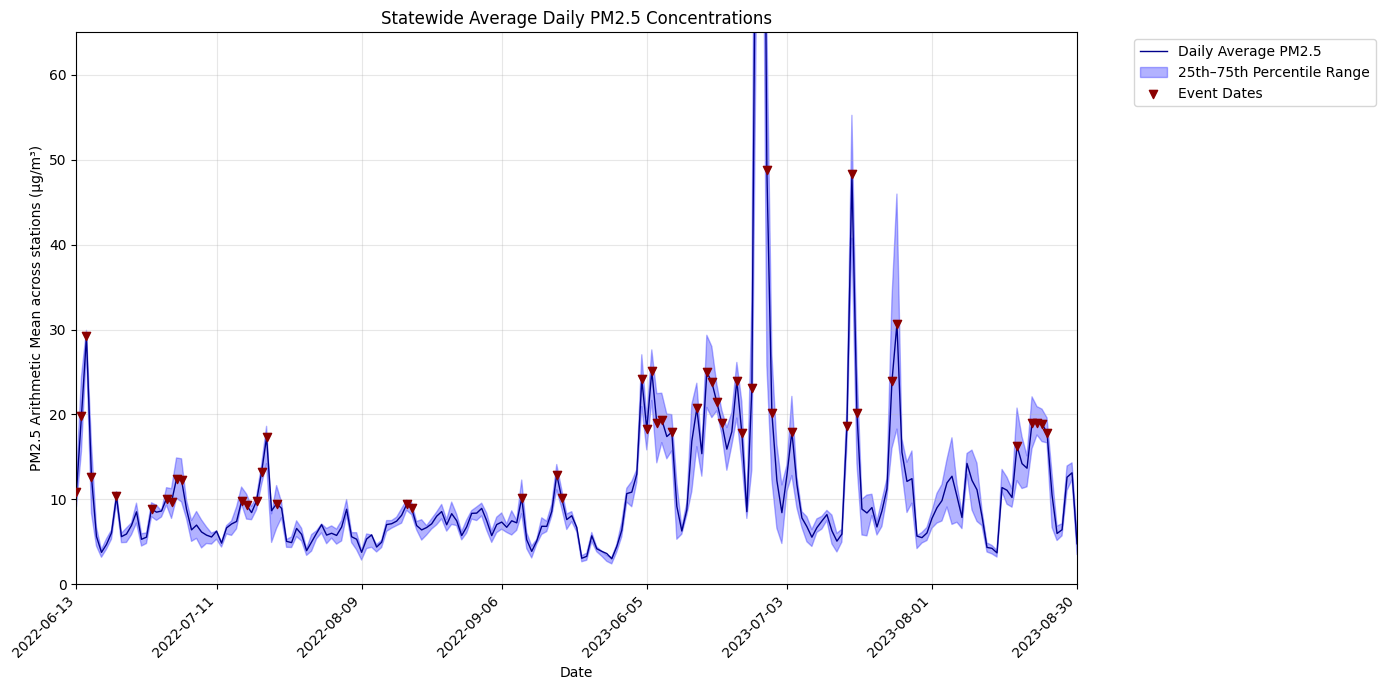

In [60]:
## The figure above would be better if I zoom in, calculate the average value across all stations
## for each day, plot the averages over time, and identify event dates.

## We need to calculate the daily average and percentiles across all available stations
ave_pm = (pm.groupby("date_local").agg(avg_pm25=("arithmetic_mean", "mean"),
        p25=("arithmetic_mean", lambda x: x.quantile(0.25)),
        p75=("arithmetic_mean", lambda x: x.quantile(0.75)),
        n_stations=("station_id", "nunique")
    )
    .reset_index()
    .sort_values("date_local")
)

# This study only considers summer months, so I want to compress the timeline
# of this time series by removing October through May dates.
# Each observed date gets a new sequential index.
ave_pm["plot_day"] = range(len(ave_pm))

# Identify the High Surface PM2.5 Event Dates.
event_dates = pd.to_datetime(event_dates)
ave_pm["is_event"] = ave_pm["date_local"].isin(event_dates)
events = ave_pm[ave_pm["is_event"]]

# And plot
fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(ave_pm["plot_day"],ave_pm["avg_pm25"],color="darkblue",linewidth=1,
    label="Daily Average PM2.5")

# This line is to include shading for the 25th to 75th percentile values across stations.
ax.fill_between(ave_pm["plot_day"],ave_pm["p25"],ave_pm["p75"],color="blue",
    alpha=0.3,label="25th–75th Percentile Range")

# This line is to include markers for the event dates.
ax.scatter(events["plot_day"],events["avg_pm25"],color="darkred",marker="v",
    s=35,label="Event Dates", zorder=3)

## Set x-axis tick locations to actual dates
tick_days = np.linspace(800, 1000, 8, dtype=int)
date_ticks = ave_pm.set_index("plot_day")["date_local"]
tick_dates = date_ticks.loc[tick_days]

ax.set_xticks(tick_days)
ax.set_xticklabels(pd.to_datetime(tick_dates).dt.strftime("%Y-%m-%d"),
    rotation=45, ha="right")

# For this example, I zoomed in to be able to visual the results better.
plt.xlabel("Date")
plt.ylabel("PM2.5 Arithmetic Mean across stations (µg/m³)")
plt.title("Statewide Average Daily PM2.5 Concentrations")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xlim(800, 1000)
plt.ylim(0, 65)
plt.tight_layout()
plt.show()

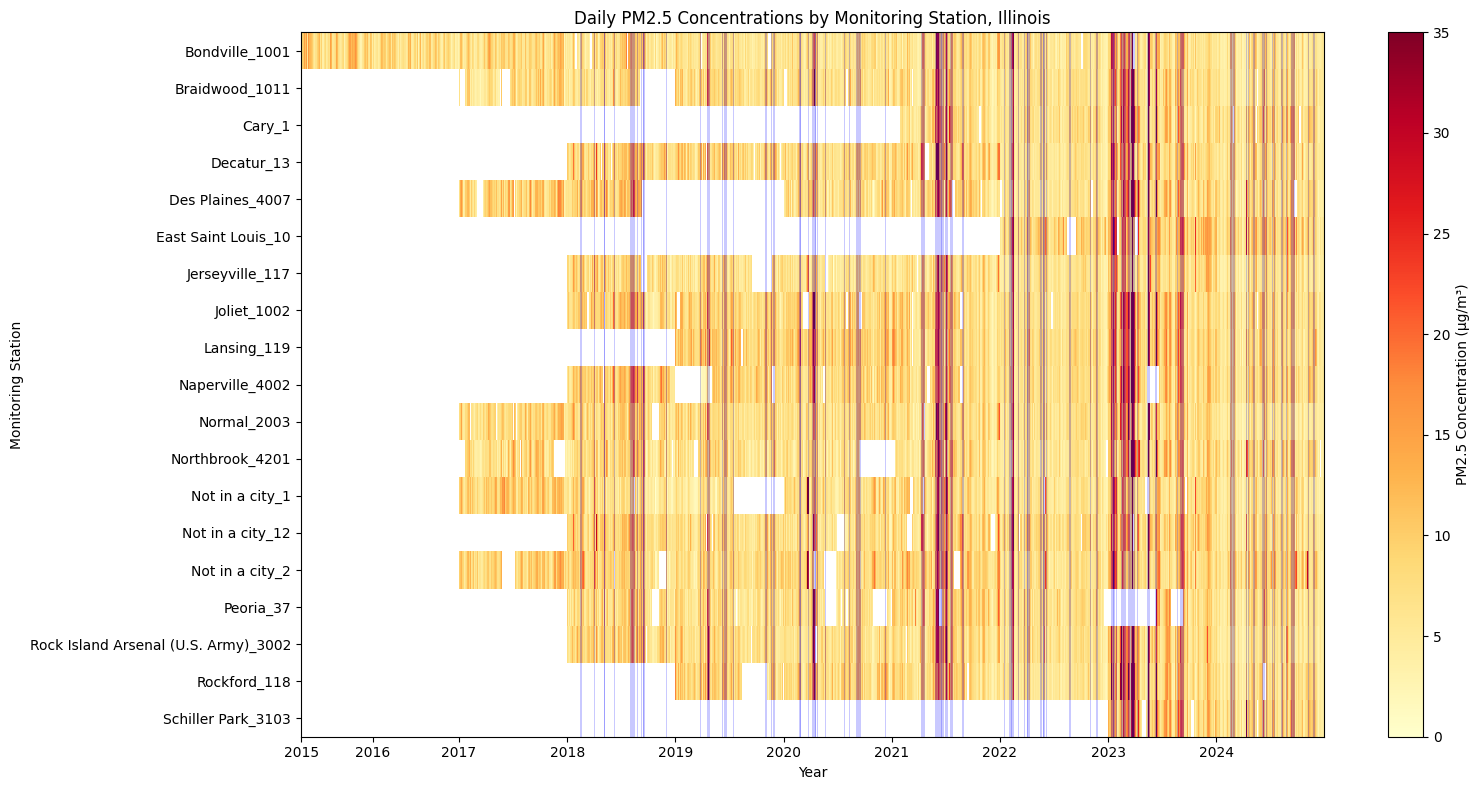

In [43]:
## The code in this cell block was developed using AI (ChatGPT).
##------

## Next up is creating a heatmap of data per day and per station, and identifying
## event dates across stations

# Ensure dates are datetime
pm["date_local"] = pd.to_datetime(pm["date_local"])

# Average PM2.5 for each station on each date
station_daily = (
    pm.groupby(["station_id", "date_local"])["arithmetic_mean"]
    .mean()
    .reset_index()
)

# Put stations in rows and dates in columns
heatmap_data = station_daily.pivot(
    index="station_id",
    columns="date_local",
    values="arithmetic_mean"
)

# Sort dates chronologically
heatmap_data = heatmap_data.sort_index(axis=1)
heatmap_data = heatmap_data.sort_index()

## and plot
fig, ax = plt.subplots(figsize=(16, 8))

heatmap = ax.imshow(heatmap_data,aspect="auto",interpolation="nearest",
    cmap="YlOrRd",vmin=0,vmax=35)

# Add colorbar, label stations, x axis label
cbar = plt.colorbar(heatmap, ax=ax)
cbar.set_label("PM2.5 Concentration (µg/m³)")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
date_columns = heatmap_data.columns
year_positions = [
    i for i, date in enumerate(date_columns)
    if date.month == 1 and date.day == 1
]

# If January 1 is absent, label the first available date per year
if len(year_positions) == 0:
    years = date_columns.year
    year_positions = [
        i for i in range(len(date_columns))
        if i == 0 or years[i] != years[i - 1]
    ]

ax.set_xticks(year_positions)
ax.set_xticklabels(
    [date_columns[i].strftime("%Y") for i in year_positions]
)

ax.set_xlabel("Year")
ax.set_ylabel("Monitoring Station")
ax.set_title("Daily PM2.5 Concentrations by Monitoring Station, Illinois")

# Add vertical lines for event dates
event_dates = pd.to_datetime(event_dates)

for event_date in event_dates:
    # Find the column corresponding to this event date
    if event_date in heatmap_data.columns:
        event_position = heatmap_data.columns.get_loc(event_date)

        ax.axvline(
            x=event_position,
            color="blue",
            linewidth=0.5,
            alpha=0.3
        )
plt.tight_layout()
plt.show()

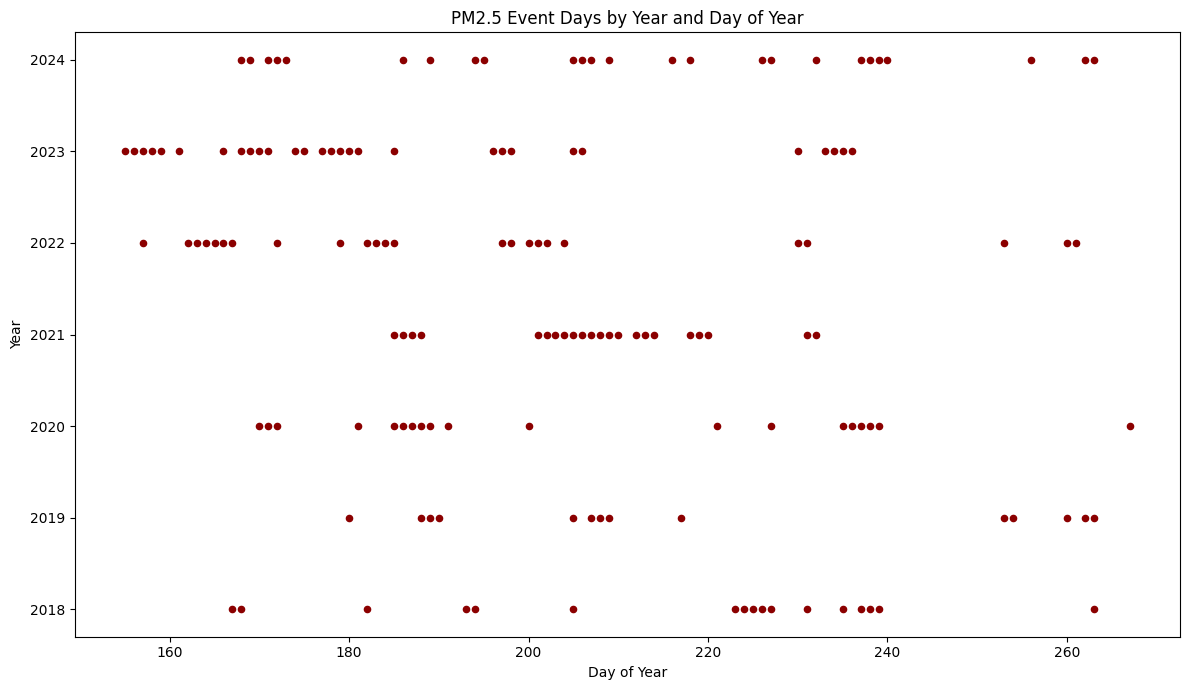

In [44]:
## I want to visualize the days in each year that qualified as High Surface PM2.5 events.

## Establish one row per date where at least one station met both criteria
pm_event_days = (pm.loc[pm["meets_both_criteria"], ["date_local"]]
      .drop_duplicates().copy())

## Make pm_event_dates into datetime format, and isolate day and year variables.
pm_event_days["date_local"] = pd.to_datetime(pm_event_days["date_local"])
pm_event_days["year"] = pm_event_days["date_local"].dt.year
pm_event_days["day_of_year"] = pm_event_days["date_local"].dt.dayofyear

## and plot -
fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(pm_event_days["day_of_year"], pm_event_days["year"], s=20, color="darkred")

ax.set_xlabel("Day of Year")
ax.set_ylabel("Year")
ax.set_title("PM2.5 Event Days by Year and Day of Year")
ax.set_yticks(sorted(pm_event_days["year"].unique()))

plt.tight_layout()
plt.show()

In [45]:
## This cell was used to identify 3 cluster locations, based on stations with available data,
## that are generally representative of statewide conditions.

## These cluster locations were applied in HYSPLIT for tracking the origin of these air masses.

from sklearn.cluster import KMeans

# K-means clustering
kmeans = KMeans(n_clusters=3,random_state=42,n_init=10)
stations['cluster'] = kmeans.fit_predict(stations[['latitude', 'longitude']])
cluster_centers = pd.DataFrame(kmeans.cluster_centers_,columns=['latitude','longitude'])
cluster_centers


/tmp/ipykernel_583/2942179511.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stations['cluster'] = kmeans.fit_predict(stations[['latitude', 'longitude']])


,latitude,longitude
0,40.413667,-89.340209
1,41.861337,-88.098608
2,38.492976,-89.729593


## Testing with subset of data

This is hidden and commented out because it does not need to be run again.

In [46]:
# Filter subset by station and year
# stations selected randomly based on stations with good coverage
# pm_daily_3stations = pm_daily_filtered[
#    (pm_daily_filtered['station_id'].isin(['Joliet_1002', 'Lansing_119', 'Des Plaines_4007'])) &
#    (pd.to_datetime(pm_daily_filtered['date_local']).between('2024-07-01', '2024-07-31'))].copy()

In [47]:
# from google.colab import files
# pm_daily_3stations.to_excel('pm_daily_3stations_2021_2024.xlsx', index=False)
# files.download('pm_daily_3stations_2021_2024.xlsx')

In [48]:
# pm = pm_daily_3stations

In [49]:
## I also want to view a time series of data points for each station
## First make sure data is sorted by date
## Convert date_local to datetime
# pm["date_local"] = pd.to_datetime(pm["date_local"])
# pm = pm.sort_values("date_local").copy()
# pm["plot_day"] = pm.groupby("date_local").ngroup()

## Create the plot
# plt.figure(figsize=(14, 7))

## loop through each unique station id, and plot arithmetic mean over time
# for station in pm["station_id"].unique():
#    station_data = pm[pm["station_id"] == station]

#    plt.plot(
#        station_data["plot_day"],
#        station_data["arithmetic_mean"],
#        label=station,
#        linewidth=1
#    )

#plt.xlabel("Date")
#plt.ylabel("PM2.5 Arithmetic Mean (µg/m³)")
#plt.title("Daily PM2.5 Concentrations by Monitoring Station")
#plt.legend(title="Station ID", bbox_to_anchor=(1.05, 1), loc="upper left")
#plt.grid(True, alpha=0.3)
#plt.ylim(0, 85)
#plt.tight_layout()
#plt.show()

In [50]:
## To determine thresholds, first need to group by station id and by year
## First extract year from date_local
#pm["year"] = pm["date_local"].dt.year

# Group by station and year
#station_year_groups = pm.groupby(["station_id", "year"])

# Calculate percentiles for each station-year
#station_year_p75 = station_year_groups["arithmetic_mean"].quantile(0.75)
#station_year_p90 = station_year_groups["arithmetic_mean"].quantile(0.90)

## reset index so columns behave for merging back into main df
## "sy" stands for station-year
#station_year_p75 = station_year_p75.reset_index(name='sy_p75')
#station_year_p90 = station_year_p90.reset_index(name='sy_p90')

## merge back into daily data df.
#pm = pm.merge(station_year_p75,on=['station_id','year'])
#pm = pm.merge(station_year_p90,on=['station_id','year'])

In [51]:
## Checkpoint
## Create verification table to check whether threshold values make sense, and were
## calculated indiviudally per station and per year
#station_year_thresholds = station_year_p75.merge(station_year_p90,on=["station_id", "year"])
#print(station_year_thresholds.to_string(index=False))

verified by hand (excel) that these threshold values are correct!

In [52]:
## Checkpoint
## Filter to one station and visualize thresholds
#station_data = pm[
#    (pm["station_id"] == "Des Plaines_4007")].sort_values("date_local")

## Get the station-year thresholds (same for every row in this group)
#p75 = station_data["sy_p75"].iloc[0]
#p90 = station_data["sy_p90"].iloc[0]

## Plot
#fig, ax = plt.subplots(figsize=(14, 6))
#ax.plot(station_data["date_local"],station_data["arithmetic_mean"],label="Daily PM2.5")

## Add threshold lines
#ax.axhline(p75, linestyle="--", linewidth=1.5, color='orange',label=f"P75 = {p75:.2f}")
#ax.axhline(p90, linestyle="--", linewidth=1.5, color='darkred',label=f"P90 = {p90:.2f}")
#ax.set_xlabel("Date")
#ax.set_ylabel("PM2.5 Arithmetic Mean (µg/m³)")
#ax.set_title("Summer Daily PM2.5 Concentrations — Normal_2003 (2023)")
#ax.legend()
#ax.grid(True, alpha=0.3)

#plt.tight_layout()
#plt.show()

In [53]:
## create Boolean (t/f) column for whether each day exceeds the applicable station-year thresholds
#pm["exceeds_p75"] = pm["arithmetic_mean"] > pm["sy_p75"]
#pm["exceeds_p90"] = pm["arithmetic_mean"] > pm["sy_p90"]

# ---Criteria 1---
## Adding a column for whether date meets criteria 1
#pm["meets_criteria1"] = pm["exceeds_p90"]

# Count stations exceeding P90 on each date
#n_stations_exceeds_p90 = (
#    pm[pm["exceeds_p90"]]
#    .groupby("date_local")["station_id"]
#    .nunique()
#    .rename("n_stations_exceeds_p90")
#    .reset_index()
#)
# Merge counts back into pm
#pm = pm.merge(n_stations_exceeds_p90, on="date_local", how="left")

#pm["n_stations_exceeds_p90"] = pm["n_stations_exceeds_p90"].fillna(0)

# At least one station must exceed P90
#pm["meets_criteria1"] = pm["n_stations_exceeds_p90"] >= 1

# ---Criteria 2---
## Identify the number of unique stations that exceed their p75 on each date
## First, making a temporary df holding only observations where the station exceeds its P75
#p75_exceed = pm[pm['exceeds_p75']].copy()

# Count stations exceeding P75 on each date
#n_stations_exceeds_p75 = (
#    p75_exceed.groupby("date_local")["station_id"]
#    .nunique()
#    .rename("n_stations_exceeds_p75")
#    .reset_index()
#)

## Merge counts back into the pm dataframe
#pm = pm.merge(n_stations_exceeds_p75, on="date_local", how="left")

## Flag dates when at least half stations exceed P75
#pm["meets_criterion2"] = pm["n_stations_exceeds_p75"] >= np.ceil(pm["station_id"].nunique() / 2)

# ---Event Dates---
#pm["meets_both_criteria"] = (pm["meets_criteria1"] & pm["meets_criterion2"])
#event_dates = (pm.loc[pm['meets_both_criteria'], 'date_local'].drop_duplicates().sort_values())
#print(event_dates)

In [54]:
## Count event dates per year
#event_dates_per_year = event_dates.groupby(event_dates.dt.year).size()
#print(event_dates_per_year)

Each date was verified by hand!

In [55]:
## I want to create a time-series plot that shows data across all the stations
## and includes markers for each event date

## Create the plot
#plt.figure(figsize=(14, 7))

## loop through each unique station id, and plot arithmetic mean over time
## stations can be the same color - individual station values don't matter for this plot
#for station in pm["station_id"].unique():
#    station_data = pm[pm["station_id"] == station]

#    plt.plot(station_data["plot_day"],station_data["arithmetic_mean"],
#        color="darkblue",linewidth=1,alpha=0.5)

## Then I want to add markers for event dates
## first make sure my event_dates series is saved as datetime
#event_dates = pd.to_datetime(event_dates)

## Get the plot_day corresponding to each event date
#event_plot_days = (pm.loc[pm["date_local"].isin(event_dates), ["date_local", "plot_day"]]
#    .drop_duplicates())

## Plot event markers along the top of the chart
#plt.scatter(event_plot_days["plot_day"],[50] * len(event_plot_days),
#    color="darkred",marker="v",s=50,label="Event Date",zorder=5)

#plt.xlabel("Date")
#plt.ylabel("PM2.5 Arithmetic Mean (µg/m³)")
#plt.title("Daily PM2.5 Concentrations by Monitoring Station")
#plt.legend(title="Station ID", bbox_to_anchor=(1.05, 1), loc="upper left")
#plt.grid(True, alpha=0.3)
#plt.ylim(0, 65)
#plt.tight_layout()
#plt.show()


In [56]:
## This figure would be better if I calculate the average value across all stations
## for each day, and plot the average over time and identify event dates

## Ensure dates are datetime
#pm["date_local"] = pd.to_datetime(pm["date_local"])

## Calculate daily average and percentiles across stations
#ave_pm = (pm.groupby("date_local").agg(
#        avg_pm25=("arithmetic_mean", "mean"),
#        p25=("arithmetic_mean", lambda x: x.quantile(0.25)),
#        p75=("arithmetic_mean", lambda x: x.quantile(0.75)),
#        n_stations=("station_id", "nunique")
#    )
#    .reset_index()
#    .sort_values("date_local")
#)

# --- 2. Compress the timeline by removing October-May ---
# Each observed date gets a sequential index
#ave_pm["plot_day"] = range(len(ave_pm))

# --- 3. Identify event dates ---
#event_dates = pd.to_datetime(event_dates)
#ave_pm["is_event"] = ave_pm["date_local"].isin(event_dates)

#vents = ave_pm[ave_pm["is_event"]]

# --- 4. Plot ---
#fig, ax = plt.subplots(figsize=(14, 7))

#ax.plot(ave_pm["plot_day"],ave_pm["avg_pm25"],color="darkblue",linewidth=1,
#    label="Daily Average PM2.5")

# Shaded range: 25th to 75th percentile across stations
#ax.fill_between(ave_pm["plot_day"],ave_pm["p25"],ave_pm["p75"],color="blue",
#    alpha=0.3,label="25th–75th Percentile Range")

# Highlight event dates
#ax.scatter(events["plot_day"],events["avg_pm25"],color="darkred",marker="v",
#    s=35,label="Event Dates", zorder=3)

#plt.xlabel("Date")
#plt.ylabel("PM2.5 Arithmetic Mean across stations (µg/m³)")
#plt.title("Daily PM2.5 Concentrations by Monitoring Station")
#plt.grid(True, alpha=0.3)
#plt.ylim(0, 65)
#plt.tight_layout()
#plt.show()